# A planet in a gap between inclined rings

[`PolarDisk`](polar_disk.md) describes a disk by a radial profile $I_0(r)$ in the plane of the disk, tilted by `inc` and rotated by `pa`. Its visibility is the Hankel transform of the profile, normalized to one at zero baseline,

$$
V(q) = \frac{\int I_0(r)\, J_0(2\pi q' r)\, r\,\mathrm{d}r}{\int I_0(r)\, r\,\mathrm{d}r},
$$

with $q'$ the baseline's spatial frequency in the disk plane, so the profile can be a parametric ring or a free function. Two optional extras are used here: an azimuthal harmonic that makes the disk lopsided, and a spectral index, $I(r,\lambda) = I_0(r)(\lambda/\lambda_0)^{\alpha(r)}$. In the non-parametric form, $\ln I_0$ at $n$ radial nodes is $\sigma L z$ with $LL^\top$ a Matérn correlation matrix of length $\ell$ and $z \sim \mathcal N(0, I)$ the free parameters, so the intensity is positive for any $z$.

We simulate a star with three inclined rings, the outermost lopsided, and a planet in the gap between the second and third, observed with VLTI-like closure phases and squared visibilities at nine wavelengths. We analyze the data twice: with the family that made them (three Gaussian rings and a planet), and with one non-parametric `PolarDisk` whose profile, colour and lopsidedness are Gaussian processes. Both run at the maximum a posteriori (MAP) solution with a Laplace approximation, with no sampling. The reference page [`PolarDisk`](polar_disk.md) lists every option.

## The scene and the data

The star is a 6000 K blackbody point source; all other fluxes are relative to it at 3 microns. The rings are `PolarDisk`s with `GaussianRing` profiles at 4.5, 10 and 21.5 mas, with Gaussian widths $\sigma$ of 1.3, 1.5 and 2.4 mas and blackbodies of 1500, 900 and 600 K (so the inner ring is bluer), and the outer one has a degree-one harmonic. The geometry is chosen for the data's resolution. The longest baseline gives a half-fringe $\lambda/2B$ of 2 to 3 mas, and a ring much narrower than that leaves almost no signature in the visibilities, so the full widths at half maximum here (3.1, 3.5 and 5.7 mas) are at or above the half-fringe and the rings are 5.5 and 11.5 mas apart. The planet is a 1000 K `PointSource`. Ring radii are in the disk plane, so we place the planet there: with position angle 30° the projected major axis points along $(\sin 30^\circ, \cos 30^\circ)$ in $(\Delta\alpha, \Delta\delta)$, where sky and plane distances agree, and we put the planet at 14.4 mas on that axis to the South-West, in the gap about three ring widths from both the second and third rings (4.4 and 7.1 mas), so $(\Delta\alpha, \Delta\delta) = (-7.2, -12.47)$ mas. The first cell checks this by deprojecting. The rings are coplanar, so `scene` hands one `inc` and `pa` to all of them; the same function is fitted below.

The data mimic a low-resolution L-band run with the four unit telescopes: nine channels from 2.4 to 3.6 microns and seven hour angles, giving 378 squared visibilities (error 0.01) and 252 closure phases (error 0.5°), 567 independent data once the closure phases' correlations are accounted for. The beam, drawn in the corner of each image, is about 6 by 3 mas, so the first two rings are about two half-fringes apart. The image shows the truth at 3 microns, East to the left, with the star saturated to show the outer ring.

planet: sky separation 14.40 mas, disk-plane radius 14.40 mas (rings at 4.5, 10.0, 21.5 mas)


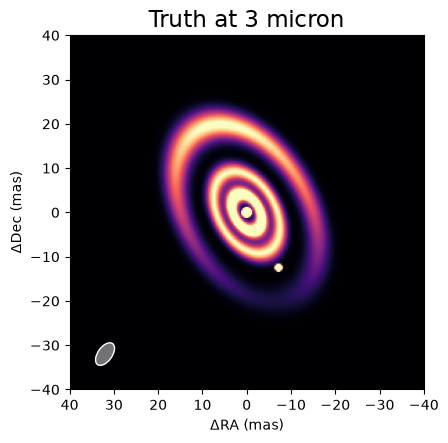

In [1]:
import sys
from pathlib import Path

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()
)
sys.path.insert(0, str(root / "src"))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist

from virgil import (
    BlackBody, GaussianRing, Harmonics, PointSource, PolarDisk,
    PolarKernel, RadialGP, System, fit, gp_priors,
)
from virgil.coverage import vlti_oidata
from virgil.imaging import beam, log_evidence
from virgil.inference import laplace_cov
from virgil.likelihood import whitened_residuals
from virgil.priors import IsotropicInclination
from virgil.plotting import plot_model, plot_residual_map

W0 = 3.0e-6  # reference wavelength, m


def scene(inc, pa, r1, s1, f1, t1, r2, s2, f2, t2, r3, s3, f3, t3,
          h_re, h_im, dra, ddec, fp, tp):
    """Star, three coplanar rings and a planet; one inc and pa for the rings."""
    def ring(r0, sigma, flux, temp, **kw):
        return PolarDisk(GaussianRing(r0, sigma), inc=inc, pa=pa, n_r=48,
                         flux=BlackBody(flux, temp, W0), **kw)
    return System(
        star=PointSource(flux=BlackBody(1.0, 6000.0, W0)),
        ring1=ring(r1, s1, f1, t1),
        ring2=ring(r2, s2, f2, t2),
        ring3=ring(r3, s3, f3, t3, harmonics=Harmonics(re=h_re, im=h_im)),
        planet=PointSource(dra=dra, ddec=ddec, flux=BlackBody(fp, tp, W0)),
    )


truth = dict(inc=50.0, pa=30.0, r1=4.5, s1=1.3, f1=0.15, t1=1500.0,
             r2=10.0, s2=1.5, f2=0.25, t2=900.0, r3=21.5, s3=2.4, f3=0.5,
             t3=600.0, h_re=0.5, h_im=0.2, dra=-7.2, ddec=-12.471, fp=0.04,
             tp=1000.0)
truth_model = scene(**truth)


def plane_radius(dra, ddec, inc, pa):
    """Disk-plane radius of a sky offset: rotate to the major/minor axes, de-foreshorten the minor."""
    pa_r = np.radians(pa)
    major = dra * np.sin(pa_r) + ddec * np.cos(pa_r)
    minor = dra * np.cos(pa_r) - ddec * np.sin(pa_r)
    return float(np.hypot(major, minor / np.cos(np.radians(inc))))


print("planet: sky separation "
      f"{np.hypot(truth['dra'], truth['ddec']):.2f} mas, disk-plane radius "
      f"{plane_radius(truth['dra'], truth['ddec'], truth['inc'], truth['pa']):.2f} mas "
      f"(rings at {truth['r1']}, {truth['r2']}, {truth['r3']} mas)")
template = vlti_oidata(
    wavelengths_m=np.linspace(2.4e-6, 3.6e-6, 9),
    hour_angles_h=(-3, -2, -1, 0, 1, 2, 3),
    sigma_v2=0.01, sigma_cp_deg=0.5,
)
data = template.with_model(truth_model, key=jax.random.PRNGKey(0))
fig, ax = plt.subplots(figsize=(5, 4.6))
FOV = 80  # mas
plot_model(truth_model, fov_mas=FOV, npix=256, ax=ax, saturate=0.99,
           beam=beam(data), title="Truth at 3 micron")
plt.show()


## The parametric fit

The truth family has 20 parameters: shared geometry, a radius, width, flux and temperature per ring, the outer harmonic's two components, and the planet's offset, flux and temperature. Their priors are invariant ones: `IsotropicInclination` (uniform in $\cos i$) for the inclination, uniform for angles and locations (position angle, harmonic components, planet offsets), and log-uniform for scales (ring radii, widths, fluxes, temperatures). We start 5 percent from the truth, as a local optimizer needs, run `fit` (Levenberg–Marquardt) to the MAP, and take the Laplace covariance with `laplace_cov`.

The printed $\chi^2/N$ is on the quoted errors with no rescaling, and should be close to 1 for the family that made the data. The table compares each parameter with the truth in units of its Laplace standard deviation. The widths are the hardest parameters, because the narrowest ring is only a little wider than the half-fringe, and a Gaussian approximation is poor for a scale pressed against its prior edge, which matters for the evidence below.

In [2]:
priors = dict(inc=IsotropicInclination(0, 85), pa=dist.Uniform(-90, 90),
              h_re=dist.Uniform(-1, 1), h_im=dist.Uniform(-1, 1),
              dra=dist.Uniform(-20, 20), ddec=dist.Uniform(-20, 20),
              fp=dist.LogUniform(0.003, 0.3), tp=dist.LogUniform(300, 3000))
for i in (1, 2, 3):
    priors |= {f"r{i}": dist.LogUniform(0.5, 40), f"s{i}": dist.LogUniform(0.1, 6),
               f"f{i}": dist.LogUniform(0.01, 2),
               f"t{i}": dist.LogUniform(300, 3000)}
start = {k: v * (1 + 0.05 * (-1) ** i) for i, (k, v) in enumerate(truth.items())}
par = fit(scene, priors, data, init=start)
names = list(priors)
x_map = np.array([float(par.values[k]) for k in names])
sigma = np.sqrt(np.diag(np.asarray(laplace_cov(x_map, names, scene, data))))
print(f"chi2 = {par.info['chi2'][0]:.0f} for N = {par.info['ndata'][0]} "
      f"independent data (chi2/N = {par.info['chi2'][0] / par.info['ndata'][0]:.2f}), "
      f"converged: {par.info['converged']}")
print(f"{'':>6}{'truth':>9}{'MAP':>9}{'Laplace sd':>12}")
for k, x, s in zip(names, x_map, sigma):
    print(f"{k:>6}{truth[k]:9.3f}{x:9.3f}{s:12.3f}")


chi2 = 572 for N = 567 independent data (chi2/N = 1.01), converged: True
          truth      MAP  Laplace sd
   inc   50.000   50.108       0.205
    pa   30.000   29.968       0.277
  h_re    0.500    0.600       0.049
  h_im    0.200    0.229       0.021
   dra   -7.200   -7.254       0.026
  ddec  -12.471  -12.488       0.027
    fp    0.040    0.041       0.001
    tp 1000.000 1021.563      26.289
    r1    4.500    4.465       0.072
    s1    1.300    1.296       0.169
    f1    0.150    0.165       0.015
    t1 1500.000 1285.476      71.295
    r2   10.000    9.940       0.122
    s2    1.500    1.519       0.130
    f2    0.250    0.277       0.015
    t2  900.000  940.208      29.298
    r3   21.500   21.488       0.029
    s3    2.400    2.403       0.042
    f3    0.500    0.454       0.019
    t3  600.000  582.920       9.105


## The non-parametric fit

Now the model that does not know about rings. One `PolarDisk` has a `RadialGP` profile on 48 nodes between 2 and 30 mas, with Matérn-3/2 correlation length $\ell = 5$ mas and $\sigma = 2$ on $\ln I_0$. Its `Harmonics(degree=1, prior=PolarKernel(...))` has an amplitude and phase that are Gaussian processes in radius, and its `spectral_index` is another `RadialGP`. The low harmonic degree stops the disk absorbing the planet, a compact, strongly asymmetric source, which keeps its parametric form with the star. `gp_priors` writes the standard-normal priors of every latent. The geometry, total disk flux and planet start at the parametric MAP, and the geometry is held at those values.

The hyperparameters are fixed by hand, not fitted, and here they are set from the scale of this scene, which a real analysis would not know (it would sample them, or compare evidences as below). The visibility is normalized, so only the variation of $\ln I_0$ with radius matters, not its mean.

- **Profile, $\sigma = 2$.** Where the rings' wings overlap the true profile is shallow in the logarithm, even where it looks like a gap in a linear image: $\ln I_0$ has a standard deviation of about 1.6 over 2 to 30 mas, and the two gaps are only 1.5 and 4 e-folds below their neighbouring peaks. A much larger $\sigma$ would license contrasts and roughness that the data cannot test.
- **Profile, $\ell = 5$ mas.** A Matérn length is not a feature width: a squared-exponential bump with the same curvature has width $\ell/\sqrt3$, here 2.9 mas. That is wider than the inner two rings' widths (1.3 and 1.5 mas) and a little wider than the outer one's (2.4 mas), so this prior smooths the inner rings rather than matching them: $\ell = 2$ mas (1.2 mas) is the length that matches the inner two, and about 4 mas the outer one. No length is the right one. This choice is a compromise between the half-fringe, below which the data cannot test structure, and the prior's slope. At $\ell = 5$ mas the prior's typical slope of $\ln I_0$, $\sqrt3\sigma/\ell \approx 0.7$ nat/mas, matches the true profile's (about 0.8 nat/mas rms).
- **Spectral index, $\sigma = 2.5$, $\ell = 4$ mas.** The three blackbodies have slopes $-1.7$, $0.35$ and $3.0$ at 3 microns, so the index must be able to change by several units between the rings. Its prior spread is comparable to the three slopes, and its length is a little shorter than the profile's so that it can switch within a gap.
- **Harmonics, $\ell_r = 5$ mas, $\sigma = 0.5$.** Only the outer ring is lopsided, so the first-order coefficients must turn on over several mas beyond the second ring. The amplitude $\sigma$ is of the order of the true components. With degree 1 the azimuthal length `ell_theta` has no effect.

The inner edge is at 2 mas, at the half-fringe. With the edge at 0.5 mas an earlier attempt (with a different scene) put about a quarter of the disk's light into an unresolved core that traded off against the star's flux, which the data cannot separate; at 2 mas the fit cannot hide light in the centre, though some trade with the star may remain. The outer edge is 3.5 widths beyond the outer ring, so less than one percent of the rings' light lies outside the model. The printed lines give $\chi^2/N$ on the quoted errors, to compare with the parametric fit's, the planet's position and flux against both the parametric fit and the truth, and the disk flux.

In [3]:
v = par.values
r_in, r_out = 2.0, 30.0
ell_gp = 5.0  # profile correlation length (mas); see the text
disk = PolarDisk(
    RadialGP(r_in, r_out, sigma=2.0, ell=ell_gp, n=48),
    harmonics=Harmonics(degree=1, prior=PolarKernel(
        ell_r=5.0, ell_theta=8.0, sigma=0.5, n=10, r_in=r_in, r_out=r_out)),
    spectral_index=RadialGP(r_in, r_out, sigma=2.5, ell=4.0, n=22),
    wavel0=W0, inc=v["inc"], pa=v["pa"], n_r=48,
    flux=v["f1"] + v["f2"] + v["f3"],
)
gp = System(
    star=PointSource(flux=BlackBody(1.0, 6000.0, W0)),
    disk=disk,
    planet=PointSource(dra=v["dra"], ddec=v["ddec"],
                       flux=BlackBody(v["fp"], v["tp"], W0)),
)
gp_priors_ = gp_priors(gp) | {
    "disk.flux": dist.LogUniform(0.05, 5.0),
    "planet.dra": dist.Uniform(-20, 20), "planet.ddec": dist.Uniform(-20, 20),
    "planet.flux.ratio": dist.LogUniform(0.003, 0.3),
    "planet.flux.temperature": dist.LogUniform(300, 3000),
}
gpfit = fit(gp, gp_priors_, data)
gv = gpfit.values
true_disk_flux = truth["f1"] + truth["f2"] + truth["f3"]
print(f"chi2 = {gpfit.info['chi2'][0]:.0f} for N = {gpfit.info['ndata'][0]} "
      f"independent data (chi2/N = {gpfit.info['chi2'][0] / gpfit.info['ndata'][0]:.2f}), "
      f"converged: {gpfit.info['converged']}, {gpfit.info['steps']} steps")
print(f"planet offset (dra, ddec) = ({gv['planet.dra']:.2f}, {gv['planet.ddec']:.2f}) mas "
      f"(parametric: {v['dra']:.2f}, {v['ddec']:.2f}; "
      f"truth {truth['dra']:.2f}, {truth['ddec']:.2f})")
print(f"planet flux at 3 micron = {gv['planet.flux.ratio']:.3f} of the star "
      f"(parametric: {v['fp']:.3f}; truth {truth['fp']:.3f})")
print(f"disk flux at 3 micron = {gv['disk.flux']:.2f} "
      f"(parametric rings: {v['f1'] + v['f2'] + v['f3']:.2f}; truth {true_disk_flux:.2f})")


chi2 = 648 for N = 567 independent data (chi2/N = 1.14), converged: True, 64 steps
planet offset (dra, ddec) = (-7.25, -12.50) mas (parametric: -7.25, -12.49; truth -7.20, -12.47)
planet flux at 3 micron = 0.041 of the star (parametric: 0.041; truth 0.040)
disk flux at 3 micron = 0.89 (parametric rings: 0.90; truth 0.90)


## The evidence, parametric against Gaussian process

For the parametric model the Laplace evidence is $\log Z \approx -\tfrac12\chi^2 + \log\pi(\hat\theta) + \tfrac d2\log 2\pi + \tfrac12\log\det\Sigma$, and `log_evidence` computes the equivalent for the Gaussian-process latents, $-\tfrac12\chi^2 - \tfrac12|z|^2 - \tfrac12\log\det(I + J^TJ)$. The two share a normalization, so only their difference means anything, and it is not a calibrated Bayes factor, for two reasons that pull opposite ways. The Gaussian-process value holds every non-latent parameter (disk flux, planet, and geometry, which was tuned on these data) at its MAP with no Occam factor, which favours the Gaussian process. The parametric family contains the truth, which no real analysis can assume, and it marginalizes all 20 parameters, which favours the parametric model. The Laplace approximation is also rough for the width pressed against its prior edge.

We also refit the Gaussian process with a shorter profile length of 2 mas instead of 5, whose squared-exponential equivalent, 1.2 mas, is finer than the half-fringe. This compares two fits with the same held parameters, which is the cleaner use of the evidence, as in MacKay's framework for choosing a hyperparameter.

In [4]:
gpm = gpfit.model
# Laplace evidence of the parametric fit: log L + log prior + (d/2) log 2 pi
# + (1/2) log det Sigma, in the same data normalization as log_evidence.
cov = np.asarray(laplace_cov(x_map, names, scene, data))
chi2_par = float(np.sum(np.asarray(whitened_residuals(par.model, data)) ** 2))
log_prior = sum(float(priors[k].log_prob(par.values[k])) for k in names)
logz_par = (-0.5 * chi2_par + log_prior + 0.5 * len(names) * np.log(2 * np.pi)
            + 0.5 * np.linalg.slogdet(cov)[1])
ell_alt = 2.0
logz = {}
for ell in (ell_gp, ell_alt):
    f = gpfit if ell == ell_gp else fit(gp.set("disk.profile.ell", ell), gp_priors_, data)
    logz[ell] = float(log_evidence(f, data, path="disk"))
print(f"parametric (20 parameters, Laplace-marginalized): log Z = {logz_par:8.1f}")
for ell, z in logz.items():
    print(f"GP (other parameters at MAP), profile length scale {ell:4.2f} mas: log Z = {z:8.1f}"
          + ("  (used below)" if ell == ell_gp else ""))
print(f"log Z(ell = {ell_gp:g}) - log Z(ell = {ell_alt:g}) = {logz[ell_gp] - logz[ell_alt]:.1f}; "
      f"parametric - GP = {logz_par - logz[ell_gp]:.1f}")


parametric (20 parameters, Laplace-marginalized): log Z =   -381.7
GP (other parameters at MAP), profile length scale 5.00 mas: log Z =   -414.4  (used below)
GP (other parameters at MAP), profile length scale 2.00 mas: log Z =   -412.7
log Z(ell = 5) - log Z(ell = 2) = -1.6; parametric - GP = 32.6


## What the data taught the Gaussian process

The parametric model is told where the rings are, so its $\log Z$ is expected to be the higher of the two; the printed difference says by how much. The two length scales, 5 and 2 mas, have the evidences printed above. A difference of a few nats between them is within what a Laplace evidence conditional on the fitted parameters can support, so where it is that small **the data do not measure the profile's length scale**: it is a prior choice, not a result, and the fine structure of the posterior is set by it wherever the data are silent. Three points keep this honest.

- A Matérn length is not a feature width. A squared-exponential bump with the same curvature as Matérn-3/2 has width $\ell/\sqrt3$: 2.9 mas for $\ell = 5$ mas and 1.2 mas for 2 mas. The ring widths are 1.3, 1.5 and 2.4 mas, so 2 mas matches the inner two rings and 5 mas is wider than all three (nearest the outer one). Neither is the right length, and 2 mas asks for structure below the half-fringe.
- The hyperparameters were set from the truth's scale (above), which a real analysis cannot do: $\sigma = 2$ is of the order of the true profile's standard deviation in $\ln I_0$, and the prior's typical slope is close to the true profile's. A prior much rougher than the scene, such as $\sigma = 3$ with $\ell = 1.5$ mas, has a typical slope of $\ln I_0$ of $\sqrt3\sigma/\ell \approx 3.5$ nat/mas, against about 0.8 nat/mas rms for the truth. Roughness is quoted as this slope, which scales with $\sigma$, and not as a number of local maxima, which does not depend on $\sigma$ and, for a Matérn-3/2 process, is infinite in the continuum.
- The data cannot resolve scales below the half-fringe of 2 to 3 mas, in either fit. Any structure the Gaussian-process band shows at those scales, and its behaviour at the inner edge, where the profile trades light with the star, is the prior and not resolved structure.

The panels compare the prior of the profile and of the spectral index (16 to 84 percent of draws at the fixed hyperparameters) with draws from the Laplace posterior of the latents, $\mathcal N(z_0, (I + J^TJ)^{-1})$, the approximation the evidence uses. Only the latents vary; geometry, planet and disk flux stay at their MAP values, so the bands are narrower than the full posterior.

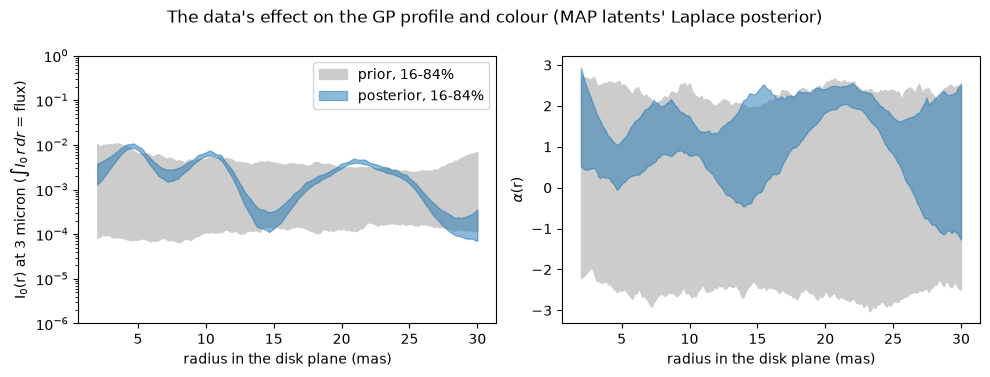

In [5]:
latents = ["disk.profile.z", "disk.harmonics.z", "disk.spectral_index.z"]
z0 = [np.asarray(gpm.get(p)) for p in latents]
flat0 = jnp.concatenate([jnp.ravel(z) for z in z0])


def residuals(flat):
    m, k = gpm, 0
    for p, z in zip(latents, z0):
        m = m.set(p, flat[k:k + z.size].reshape(z.shape))
        k += z.size
    return whitened_residuals(m, data)


# Laplace posterior of the latents, N(z0, (I + J^T J)^-1), as log_evidence uses
jac = np.asarray(jax.jacfwd(residuals)(flat0))
chol = np.linalg.cholesky(np.linalg.inv(np.eye(flat0.size) + jac.T @ jac))
rng = np.random.default_rng(0)
draws = np.asarray(flat0) + rng.standard_normal((200, flat0.size)) @ chol.T

rg = np.linspace(r_in, r_out, 200)


def profile_alpha(flat):
    """Surface brightness (unit integral times the disk flux), alpha(r), |I_1|."""
    m, k = gpm, 0
    for p, z in zip(latents, z0):
        m = m.set(p, flat[k:k + z.size].reshape(z.shape))
        k += z.size
    i0 = m.disk.profile.intensity(rg, 0.1)
    i0 = i0 / jnp.trapezoid(i0 * rg, rg) * m.disk.flux
    return (i0, m.disk.spectral_index(rg),
            jnp.abs(m.disk.harmonics.image_harmonics(rg)[1]))


post_i0, post_al, post_h1 = (
    np.asarray(x) for x in jax.vmap(profile_alpha)(jnp.asarray(draws))
)
key = jax.random.PRNGKey(1)
prior_i0 = np.asarray(gpm.disk.profile.draws(key, 200, r=rg, positive=True))
prior_i0 = prior_i0 / np.trapezoid(prior_i0 * rg, rg, axis=1)[:, None] * float(gpm.disk.flux)
prior_al = np.asarray(gpm.disk.spectral_index.draws(key, 200, r=rg))
band = lambda x: np.percentile(x, [16, 84], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, pr, po, label in zip(axes, (prior_i0, prior_al), (post_i0, post_al),
                             (r"I$_0$(r) at 3 micron ($\int I_0\,r\,dr$ = flux)", r"$\alpha$(r)")):
    ax.fill_between(rg, *band(pr), color="0.8", label="prior, 16-84%")
    ax.fill_between(rg, *band(po), color="C0", alpha=0.5, label="posterior, 16-84%")
    ax.set_xlabel("radius in the disk plane (mas)")
    ax.set_ylabel(label)
axes[0].set_yscale("log")
axes[0].set_ylim(1e-6, 1e0)
axes[0].legend()
fig.suptitle("The data's effect on the GP profile and colour (MAP latents' Laplace posterior)")
plt.tight_layout()
plt.show()


## Truth, parametric fit and deconvolution side by side

The top row shows the truth, the parametric fit and the Gaussian-process disk at 3 microns on one colour scale, with the beam in the corner; the second row shows the fits minus the truth as signed residuals (symmetric scales). The three middle panels compare the profile, colour and lopsidedness with the truth, with the blue bands from the Laplace posterior above. The truth profile is the sum of the three Gaussians, normalized so that $\int I_0\, r\,dr$ is the flux; the colour is the intensity-weighted logarithmic slope of the three blackbodies at 3 microns; the lopsidedness is the outer ring's first harmonic weighted by its share of the light. The spectra panel integrates the Gaussian-process disk over three radial windows, split at the minima of the true profile between the rings, against the corresponding blackbodies. The bottom row shows both fits' residuals over the quoted errors, with their root mean squares, and the cell prints the root-mean-square error of $\ln I_0$ of the two fitted profiles against the truth, over the radii where the truth is within $e^{-6}$ of its peak.

Read the figure for these things: whether the Gaussian-process profile has a bump at each true ring radius and a minimum in the gap where the planet sits; how far its band widens beyond the outer ring, where the data are silent; whether the spectral index follows the truth in each ring, or fails in the innermost window, where the edge of the profile has little leverage; whether the lopsidedness is near the truth beyond the second ring and near zero inside; and the residual maps, for structure at the outer ring or the planet. A power law in wavelength only approximates a blackbody over this band, as the dashed lines of the spectra panel show.

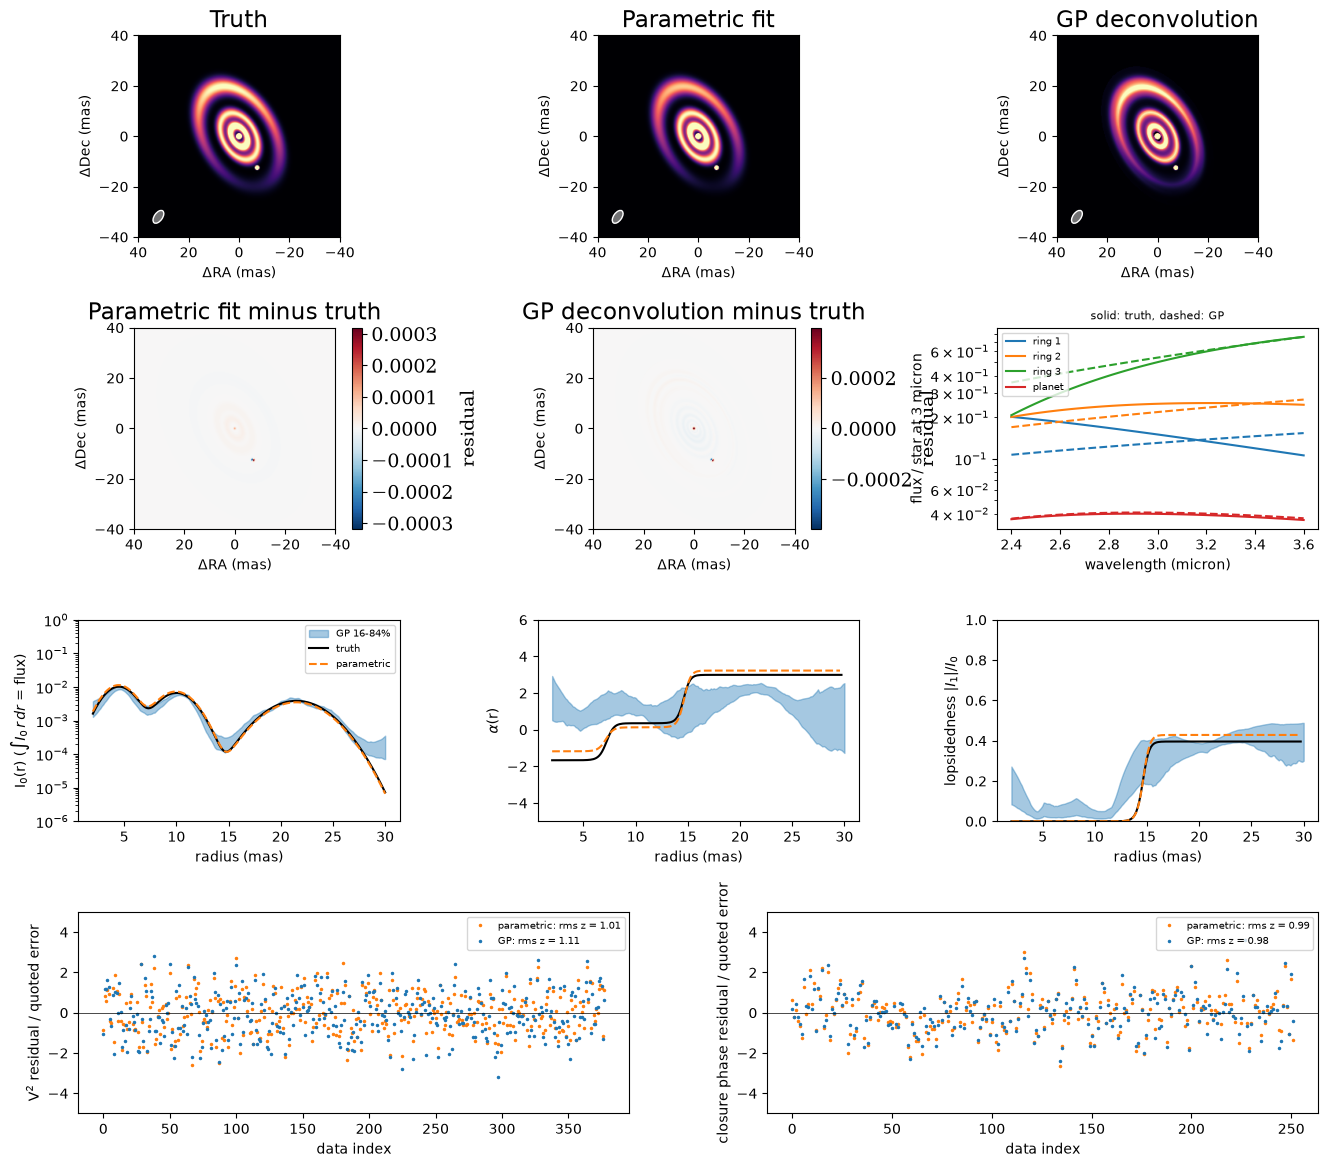

rms error of ln I0 over 2.0-29.0 mas (truth within e^-6 of its peak): GP 0.33, parametric 0.10


In [6]:
par_model, bm = par.model, beam(data)
y, err = data.flatten_data()
n_vis = np.asarray(data.vis).size
lam = np.linspace(2.4e-6, 3.6e-6, 50)
alpha_of = lambda t: float(jax.grad(lambda l: jnp.log(BlackBody(1.0, t, W0)(l)))(W0) * W0)


def truth_profile(r, p):
    """I0(r) at 3 micron, the intensity-weighted alpha(r) and the harmonic |I_1|(r).

    Each ring is exp[-(r - r_i)^2 / 2 s_i^2], as GaussianRing has it, normalized by
    sqrt(2 pi) s_i r_i so that the integral of I0 r dr is the ring's flux (exact to
    <0.1 percent here, where r_i >> s_i).
    """
    g = [p[f"f{i}"] * np.exp(-0.5 * ((r - p[f"r{i}"]) / p[f"s{i}"]) ** 2)
         / (np.sqrt(2 * np.pi) * p[f"s{i}"] * p[f"r{i}"]) for i in (1, 2, 3)]
    a = [alpha_of(p[f"t{i}"]) for i in (1, 2, 3)]
    h3 = abs(np.asarray(Harmonics(re=p["h_re"], im=p["h_im"]).image_harmonics())[1])
    tot = sum(g) + 1e-30
    return sum(g), sum(gi * ai for gi, ai in zip(g, a)) / tot, h3 * g[2] / tot


fig = plt.figure(figsize=(16, 14))
grid = fig.add_gridspec(4, 6, hspace=0.45, wspace=1.5)
models = [(truth_model, "Truth"), (par_model, "Parametric fit"), (gpm, "GP deconvolution")]
for j, (m, name) in enumerate(models):
    plot_model(m, fov_mas=FOV, npix=256, ax=fig.add_subplot(grid[0, 2 * j:2 * j + 2]),
               saturate=0.99, beam=bm, title=name)
true_image = truth_model.render(npix=256, fov_mas=FOV)
for j, (m, name) in enumerate(models[1:]):
    ax = plot_residual_map(np.asarray(m.render(npix=256, fov_mas=FOV) - true_image), FOV,
                           ax=fig.add_subplot(grid[1, 2 * j:2 * j + 2]),
                           title=f"{name} minus truth")
    cbar = ax.images[0].colorbar  # the title names the quantity; the bar's label collided with the spectra panel
    cbar.set_label("")
    cbar.ax.tick_params(labelsize=9)
ax = fig.add_subplot(grid[2, 0:2])
i_t, a_t, h_t = truth_profile(rg, truth)
i_p, a_p, h_p = truth_profile(rg, dict(par.values))
ax.fill_between(rg, *band(post_i0), color="C0", alpha=0.4, label="GP 16-84%")
ax.plot(rg, i_t, "k", label="truth")
ax.plot(rg, i_p, "C1--", label="parametric")
ax.set(yscale="log", ylim=(1e-6, 1e0), xlabel="radius (mas)", ylabel=r"I$_0$(r) ($\int I_0\,r\,dr$ = flux)")
ax.legend(fontsize=7)
ax = fig.add_subplot(grid[2, 2:4])
ax.fill_between(rg, *band(post_al), color="C0", alpha=0.4)
ax.plot(rg, np.where(i_t > 1e-3 * i_t.max(), a_t, np.nan), "k")
ax.plot(rg, np.where(i_p > 1e-3 * i_p.max(), a_p, np.nan), "C1--")
ax.set(xlabel="radius (mas)", ylabel=r"$\alpha$(r)", ylim=(-5, 6))
ax = fig.add_subplot(grid[2, 4:6])
ax.fill_between(rg, *band(post_h1), color="C0", alpha=0.4)
ax.plot(rg, np.where(i_t > 1e-3 * i_t.max(), h_t, np.nan), "k")
ax.plot(rg, np.where(i_p > 1e-3 * i_p.max(), h_p, np.nan), "C1--")
ax.set(xlabel="radius (mas)", ylabel=r"lopsidedness $|I_1|/I_0$", ylim=(0, 1))
ax = fig.add_subplot(grid[1, 4:6])
nodes, w = (np.asarray(x) for x in gpm.disk.profile.quadrature())
frac, al = w / w.sum(), np.asarray(gpm.disk.spectral_index(nodes))
# windows split at the minima of the true profile between the ring centres
cuts = []
for a, b in [(truth["r1"], truth["r2"]), (truth["r2"], truth["r3"])]:
    inside = (rg > a) & (rg < b)
    cuts.append(float(rg[inside][np.argmin(i_t[inside])]))
for i, (lo, hi) in enumerate([(0, cuts[0]), (cuts[0], cuts[1]), (cuts[1], 99)]):
    inside = (nodes >= lo) & (nodes < hi)
    f_gp = float(gpm.disk.flux) * (frac[inside, None] * (lam / W0) ** al[inside, None]).sum(0)
    t_i = BlackBody(truth[f"f{i + 1}"], truth[f"t{i + 1}"], W0)(lam)
    ax.plot(lam * 1e6, t_i, f"C{i}", label=f"ring {i + 1}")
    ax.plot(lam * 1e6, f_gp, f"C{i}--")
ax.plot(lam * 1e6, BlackBody(truth["fp"], truth["tp"], W0)(lam), "C3", label="planet")
ax.plot(lam * 1e6, BlackBody(gv["planet.flux.ratio"], gv["planet.flux.temperature"], W0)(lam), "C3--")
ax.set(xlabel="wavelength (micron)", ylabel="flux / star at 3 micron", yscale="log")
ax.set_title("solid: truth, dashed: GP", fontsize=8)
ax.legend(fontsize=7)
for col, (sl, label) in enumerate([(slice(0, n_vis), r"V$^2$"), (slice(n_vis, None), "closure phase")]):
    ax = fig.add_subplot(grid[3, 3 * col:3 * col + 3])
    for m, name, c in [(par_model, "parametric", "C1"), (gpm, "GP", "C0")]:
        z = np.asarray(data.residuals(data.model(m)))[sl] / err[sl]
        ax.plot(z, ".", ms=3, color=c, label=f"{name}: rms z = {np.sqrt(np.mean(z**2)):.2f}")
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="data index", ylabel=f"{label} residual / quoted error", ylim=(-5, 5))
    ax.legend(fontsize=7, loc="upper right")
plt.show()

i_map = np.asarray(profile_alpha(flat0)[0])
near = i_t > i_t.max() * np.exp(-6)
rms_ln = lambda i: np.sqrt(np.mean((np.log(i[near]) - np.log(i_t[near])) ** 2))
print(f"rms error of ln I0 over {rg[near].min():.1f}-{rg[near].max():.1f} mas "
      f"(truth within e^-6 of its peak): GP {rms_ln(i_map):.2f}, parametric {rms_ln(i_p):.2f}")


## Summary

A non-parametric `PolarDisk` models the same 630 numbers as a parametric fit of the true family, without being told there are three rings: its profile, colour and lopsidedness are Gaussian processes, and the planet keeps its parametric form. Compare the figure with the truth for the ring radii, the gap, the outer ring's lopsidedness and the planet, and the printed values for the fit quality and the planet's position and flux.

The costs are visible in the printed values and the figure. The fit is expected to be worse on the quoted errors than the parametric fit that contains the truth ($\chi^2/N$ is printed for both), a power law in wavelength only approximates a blackbody, and the inner edge has to stay near the resolution. The profile's length scale is a prior choice unless the evidences above differ by much more than a few nats, and structure finer than the 2 to 3 mas half-fringe, in either fit, is not constrained by the data. The Laplace $\log Z$ comparison with the parametric model is only indicative (see above). For real data, use the two together: the Gaussian process to find structure and propose a parametric family, and the parametric fit and its evidence to confirm and measure it. Sampling the hyperparameters with NUTS and the whitened latents is the natural next step and is not done here.